# Spatial Feature Discovery — Cell2Location-Based Tissue Characterization

Six independent analyses using Cell2Location deconvolution to characterize spatial features across all 41 Visium samples:

1. **Immune Hot vs Cold Tumor Regions**
2. **Tertiary Lymphoid Structures (TLS)**
3. **Tumor Budding Zones**
4. **Hypoxic vs Normoxic Tumor**
5. **Nerve Invasion Zones (Perineural)**
6. **Vascular Invasion Zones (Lymphovascular)**

**Prerequisites:** Run the h5ad update script first so  has  and  columns.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from matplotlib.backends.backend_pdf import PdfPages
import os
import warnings
warnings.filterwarnings('ignore')

META_PATH = "/Users/adiallo/Desktop/Thesis/Data_Documents/data_all.csv"
SAMPLE_DIR = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"
OUTPUT_DIR = "/Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_Features"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ABUNDANCE_KEY = 'means_cell_abundance_w_sf'

meta = pd.read_csv(META_PATH)
meta['deident'] = meta['deident'].astype(str)

def get_mets(row):
    dist = str(row.get('Distant_Mets', 'False')).upper()
    ln = str(row.get('ln_only', 'False')).upper()
    if dist in ['TRUE', 'T']: return 'Distant_Mets'
    elif ln in ['TRUE', 'T']: return 'LN_Mets'
    return 'No_Mets'

meta['mets_group'] = meta.apply(get_mets, axis=1)

METS_ORDER = ['No_Mets', 'LN_Mets', 'Distant_Mets']
METS_PALETTE = {'No_Mets': '#3cb44b', 'LN_Mets': '#ffe119', 'Distant_Mets': '#e6194b'}
EXAMPLE_SAMPLES = {'No_Mets': '38', 'LN_Mets': '107', 'Distant_Mets': '80'}

print(f"Loaded metadata: {len(meta)} samples")
print(f"Mets distribution: {meta['mets_group'].value_counts().to_dict()}")

Loaded metadata: 57 samples
Mets distribution: {'No_Mets': 25, 'Distant_Mets': 19, 'LN_Mets': 13}


In [16]:
"""
Annotate Visium H5AD Files with Spatial Features
=================================================
Adds the following per-spot annotations to each sample:
  - region (CT/IM/Stroma/Other) — verify existing or compute
  - refined_region — verify existing or compute
  - stromal_ratio — verify existing or compute
  - immune_hot_cold — immune hot vs cold classification in tumor
  - tls_spot — putative tertiary lymphoid structure spot
  - tumor_budding — tumor budding zone
  - hypoxia_score — hypoxia gene signature score
  - pni_spot — perineural invasion zone
  - lvi_spot — lymphovascular invasion zone
  - immune_score — total immune cell abundance
  - cd8_score — CD8 T cell abundance
  - tls_score — TLS signature abundance

Saves to annotated_samples/ directory.

Run from your samples directory:
    cd /Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples
"""

import scanpy as sc
import numpy as np
import pandas as pd
import os
import warnings
from scipy.spatial import KDTree
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist

warnings.filterwarnings('ignore')

# ============================================================
# CONFIGURATION
# ============================================================
SAMPLE_DIR = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"
OUTPUT_DIR = os.path.join(SAMPLE_DIR, "annotated_samples")
ABUNDANCE_KEY = "means_cell_abundance_w_sf"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# CELL TYPE PATTERNS
# ============================================================
IMMUNE_PATTERNS = {
    'CD8_T': ['cTNI10', 'cTNI11', 'cTNI12', 'cTNI13', 'cTNI14', 'cTNI15', 'cTNI16'],
    'CD4_T': ['cTNI01', 'cTNI02', 'cTNI03', 'cTNI04', 'cTNI05', 'cTNI06', 'cTNI07'],
    'Treg': ['cTNI08', 'cTNI09'],
    'NK': ['cTNI23', 'cTNI24', 'cTNI25'],
    'B_cell': ['cB1', 'cB2', 'cB3'],
    'Plasma': ['cP1', 'cP2', 'cP3'],
    'Macrophage': ['cM01', 'cM02'],
    'DC': ['cM03', 'cM04', 'cM05', 'cM06', 'cM07', 'cM08', 'cM09'],
    'Mast': ['cMA01'],
    'Granulocyte': ['cM10'],
}

ALL_IMMUNE_PATTERNS = []
for patterns in IMMUNE_PATTERNS.values():
    ALL_IMMUNE_PATTERNS.extend(patterns)

TLS_PATTERNS = {
    'B_cell': ['cB1', 'cB2', 'cB3'],
    'TFH': ['cTNI06'],
    'DC': ['cM03', 'cM04', 'cM05'],
}

ENDO_PATTERNS = ['cS01', 'cS02', 'cS03', 'cS04', 'cS05', 'cS06', 'cS07',
                  'cS08', 'cS09', 'cS10', 'cS11', 'cS12', 'cS13', 'cS14']
LYMPHATIC_PATTERNS = ['cS06']

HYPOXIA_GENES = [
    'VEGFA', 'SLC2A1', 'LDHA', 'PGK1', 'ALDOA', 'ENO1', 'CA9',
    'BNIP3', 'NDRG1', 'ADM', 'P4HA1', 'PGAM1', 'TPI1', 'GPI',
    'GAPDH', 'PKM', 'LOX', 'BNIP3L', 'HK2', 'PDK1'
]


# ============================================================
# HELPER FUNCTIONS
# ============================================================
def get_column_matches(columns, patterns):
    matched = []
    for col in columns:
        clean = col.replace("meanscell_abundance_w_sf_", "").replace("means_cell_abundance_w_sf_", "")
        for pat in patterns:
            if clean.startswith(pat) or pat in clean:
                matched.append(col)
                break
    return matched


def get_abundance_score(abund, patterns):
    cols = get_column_matches(abund.columns, patterns)
    if len(cols) == 0:
        return np.zeros(len(abund))
    return abund[cols].sum(axis=1).values


def define_regions_spatial(adata):
    """
    Defines CT, IM, Stroma, Other using spatial boundary method.
    """
    coords = adata.obsm["spatial"]
    pixel_scale_100um = np.median(pdist(coords[:200]))

    tumor_labels = ["cancer_cancer"]
    stroma_labels = ["benign_stroma", "benign_fat", "inter", "stroma"]
    histo = adata.obs["histology"].astype(str)
    is_tumor = histo.isin(tumor_labels).values
    is_stroma = histo.isin(stroma_labels).values

    region_labels = np.array(["Other"] * adata.n_obs, dtype=object)

    tumor_coords = coords[is_tumor]
    stroma_coords = coords[is_stroma]

    if len(tumor_coords) == 0 or len(stroma_coords) == 0:
        region_labels[is_tumor] = "CT"
        region_labels[is_stroma] = "Stroma"
        return region_labels

    stroma_tree = KDTree(stroma_coords)
    dists_to_stroma, _ = stroma_tree.query(tumor_coords, k=1)
    dists_to_stroma = dists_to_stroma.ravel()

    boundary_threshold = 1.5 * pixel_scale_100um
    boundary_tumor_mask = dists_to_stroma <= boundary_threshold
    tumor_indices = np.where(is_tumor)[0]
    boundary_indices = tumor_indices[boundary_tumor_mask]

    if len(boundary_indices) == 0:
        region_labels[is_tumor] = "CT"
        region_labels[is_stroma] = "Stroma"
        return region_labels

    boundary_coords = coords[boundary_indices]
    boundary_tree = KDTree(boundary_coords)
    dists_to_boundary, _ = boundary_tree.query(coords, k=1)
    dists_to_boundary = dists_to_boundary.ravel()

    im_width = 5 * pixel_scale_100um
    is_im = dists_to_boundary <= im_width

    region_labels[is_im & (is_tumor | is_stroma)] = "IM"
    region_labels[is_tumor & (~is_im)] = "CT"
    region_labels[is_stroma & (~is_im)] = "Stroma"

    return region_labels


# ============================================================
# PROCESS EACH SAMPLE
# ============================================================
h5ad_files = sorted([f for f in os.listdir(SAMPLE_DIR) if f.endswith('.h5ad')])
# Filter to numeric sample IDs only
h5ad_files = [f for f in h5ad_files if f.replace('.h5ad', '').isdigit()]

print(f"Found {len(h5ad_files)} sample files")
print(f"Output directory: {OUTPUT_DIR}")
print("=" * 70)

for h5ad_file in h5ad_files:
    sid = h5ad_file.replace('.h5ad', '')
    print(f"\n--- Sample {sid} ---")

    adata = sc.read_h5ad(os.path.join(SAMPLE_DIR, h5ad_file))
    abund = adata.obsm[ABUNDANCE_KEY]
    coords = adata.obsm['spatial']

    # --------------------------------------------------------
    # 1. VERIFY / COMPUTE REGION ANNOTATIONS
    # --------------------------------------------------------
    if 'region' in adata.obs.columns:
        region_vals = adata.obs['region'].value_counts()
        has_im = 'IM' in region_vals.index
        has_ct = 'CT' in region_vals.index
        print(f"  region: exists (CT={region_vals.get('CT', 0)}, IM={region_vals.get('IM', 0)}, "
              f"Stroma={region_vals.get('Stroma', 0)}, Other={region_vals.get('Other', 0)})")
        if not has_im or not has_ct:
            print(f"  WARNING: Missing CT or IM — recomputing")
            adata.obs['region'] = define_regions_spatial(adata)
    else:
        print(f"  region: MISSING — computing")
        adata.obs['region'] = define_regions_spatial(adata)

    if 'refined_region' not in adata.obs.columns:
        print(f"  refined_region: MISSING — will be empty")
    else:
        print(f"  refined_region: exists")

    if 'stromal_ratio' not in adata.obs.columns:
        print(f"  stromal_ratio: MISSING — will be empty")
    else:
        print(f"  stromal_ratio: exists")

    # --------------------------------------------------------
    # 2. IMMUNE SCORES
    # --------------------------------------------------------
    immune_score = get_abundance_score(abund, ALL_IMMUNE_PATTERNS)
    cd8_score = get_abundance_score(abund, IMMUNE_PATTERNS['CD8_T'])
    adata.obs['immune_score'] = immune_score
    adata.obs['cd8_score'] = cd8_score

    # --------------------------------------------------------
    # 3. IMMUNE HOT / COLD
    # --------------------------------------------------------
    if 'refined_region' in adata.obs.columns:
        tumor_mask = adata.obs['refined_region'].isin(['Tumor_epithelial', 'Intratumoral_stroma', 'IM_tumor'])
    else:
        tumor_mask = adata.obs['histology'] == 'cancer_cancer'

    if tumor_mask.sum() > 0:
        median_immune = np.median(immune_score[tumor_mask])
        hot_cold = np.where(
            ~tumor_mask, 'non_tumor',
            np.where(immune_score > median_immune, 'immune_hot', 'immune_cold')
        )
    else:
        hot_cold = np.full(adata.n_obs, 'non_tumor')
    adata.obs['immune_hot_cold'] = pd.Categorical(hot_cold)
    n_hot = (hot_cold == 'immune_hot').sum()
    n_cold = (hot_cold == 'immune_cold').sum()
    print(f"  immune_hot_cold: {n_hot} hot, {n_cold} cold")

    # --------------------------------------------------------
    # 4. TLS SPOTS
    # --------------------------------------------------------
    b_score = get_abundance_score(abund, TLS_PATTERNS['B_cell'])
    tfh_score = get_abundance_score(abund, TLS_PATTERNS['TFH'])
    dc_score = get_abundance_score(abund, TLS_PATTERNS['DC'])
    tls_score = b_score + tfh_score + dc_score
    adata.obs['tls_score'] = tls_score

    threshold = np.percentile(tls_score, 90)
    tls_high = tls_score > threshold

    nn = NearestNeighbors(n_neighbors=min(20, len(coords))).fit(coords)
    dists, indices = nn.kneighbors(coords)
    spot_spacing = np.median(dists[:, 1])
    cluster_radius = 3 * spot_spacing

    tls_cluster = np.zeros(adata.n_obs, dtype=bool)
    for i in range(adata.n_obs):
        if not tls_high[i]:
            continue
        neighbors_in_radius = dists[i] <= cluster_radius
        tls_neighbors = tls_high[indices[i][neighbors_in_radius]]
        if tls_neighbors.sum() >= 5:
            tls_cluster[i] = True

    adata.obs['tls_spot'] = tls_cluster
    print(f"  tls_spot: {tls_cluster.sum()} spots")

    # --------------------------------------------------------
    # 5. TUMOR BUDDING
    # --------------------------------------------------------
    tumor_score = get_abundance_score(abund, ['Tumor'])

    if 'region' in adata.obs.columns:
        stroma_mask = adata.obs['region'].isin(['IM', 'Stroma'])
    else:
        stroma_mask = adata.obs['histology'] != 'cancer_cancer'

    tumor_positive = tumor_score[tumor_score > np.percentile(tumor_score, 50)]
    if len(tumor_positive) > 0:
        low_thresh = np.percentile(tumor_positive, 5)
        high_thresh = np.percentile(tumor_positive, 25)
    else:
        low_thresh, high_thresh = 0, 0

    budding_mask = stroma_mask.values & (tumor_score > low_thresh) & (tumor_score < high_thresh)
    adata.obs['tumor_budding'] = budding_mask
    print(f"  tumor_budding: {budding_mask.sum()} spots")

    # --------------------------------------------------------
    # 6. HYPOXIA SCORE
    # --------------------------------------------------------
    available_hyp = [g for g in HYPOXIA_GENES if g in adata.var_names]
    if len(available_hyp) >= 5:
        sc.tl.score_genes(adata, gene_list=available_hyp, score_name='hypoxia_score', use_raw=False)
        print(f"  hypoxia_score: computed ({len(available_hyp)} genes)")
    else:
        adata.obs['hypoxia_score'] = 0.0
        print(f"  hypoxia_score: insufficient genes ({len(available_hyp)})")

    # --------------------------------------------------------
    # 7. PERINEURAL INVASION (PNI)
    # --------------------------------------------------------
    schwann_score = get_abundance_score(abund, ['cS33'])
    schwann_thresh = np.percentile(schwann_score, 75)
    tumor_thresh = np.percentile(tumor_score, 50)
    pni_mask = (schwann_score > schwann_thresh) & (tumor_score > tumor_thresh)
    adata.obs['pni_spot'] = pni_mask
    adata.obs['schwann_score'] = schwann_score
    print(f"  pni_spot: {pni_mask.sum()} spots")

    # --------------------------------------------------------
    # 8. LYMPHOVASCULAR INVASION (LVI)
    # --------------------------------------------------------
    endo_score = get_abundance_score(abund, ENDO_PATTERNS)
    lymph_score = get_abundance_score(abund, LYMPHATIC_PATTERNS)
    endo_thresh = np.percentile(endo_score, 75)
    lvi_mask = (endo_score > endo_thresh) & (tumor_score > tumor_thresh)
    adata.obs['lvi_spot'] = lvi_mask
    adata.obs['endo_score'] = endo_score
    adata.obs['lymphatic_score'] = lymph_score
    print(f"  lvi_spot: {lvi_mask.sum()} spots")

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------
    out_path = os.path.join(OUTPUT_DIR, h5ad_file)
    adata.write_h5ad(out_path)
    print(f"  Saved: {out_path}")

print(f"\n{'=' * 70}")
print(f"All {len(h5ad_files)} samples annotated and saved to {OUTPUT_DIR}")
print(f"{'=' * 70}")

# Summary of new annotations added
print(f"\nAnnotations per spot:")
print(f"  region          — CT / IM / Stroma / Other")
print(f"  refined_region  — Tumor_epithelial / Intratumoral_stroma / IM_tumor / IM_stroma / Normal_stroma / Other")
print(f"  stromal_ratio   — continuous 0-1")
print(f"  immune_score    — total immune cell abundance")
print(f"  cd8_score       — CD8 T cell abundance")
print(f"  immune_hot_cold — immune_hot / immune_cold / non_tumor")
print(f"  tls_score       — TLS signature abundance (B + TFH + DC)")
print(f"  tls_spot        — boolean, putative TLS cluster")
print(f"  tumor_budding   — boolean, tumor budding zone")
print(f"  hypoxia_score   — hypoxia gene signature score")
print(f"  pni_spot        — boolean, perineural invasion zone")
print(f"  schwann_score   — Schwann cell abundance")
print(f"  lvi_spot        — boolean, lymphovascular invasion zone")
print(f"  endo_score      — endothelial cell abundance")
print(f"  lymphatic_score — lymphatic endothelial abundance")

Found 41 sample files
Output directory: /Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples/annotated_samples

--- Sample 0 ---
  region: exists (CT=3029, IM=1180, Stroma=2080, Other=369)
  refined_region: exists
  stromal_ratio: exists
  immune_hot_cold: 1817 hot, 1817 cold
  tls_spot: 561 spots
  tumor_budding: 278 spots
  hypoxia_score: computed (15 genes)
  pni_spot: 1661 spots
  lvi_spot: 1573 spots
  Saved: /Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples/annotated_samples/0.h5ad

--- Sample 10 ---
  region: exists (CT=3164, IM=1050, Stroma=1558, Other=366)
  refined_region: exists
  stromal_ratio: exists
  immune_hot_cold: 1843 hot, 1843 cold
  tls_spot: 527 spots
  tumor_budding: 124 spots
  hypoxia_score: computed (15 genes)
  pni_spot: 1505 spots
  lvi_spot: 1413 spots
  Saved: /Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples/annotated_samples/10.h5ad

--- Samp

In [2]:
def get_column_matches(columns, patterns):
    """Find columns matching any of the given patterns."""
    matched = []
    for col in columns:
        clean = col.replace("meanscell_abundance_w_sf_", "")
        for pat in patterns:
            if clean.startswith(pat) or pat in clean:
                matched.append(col)
                break
    return matched


def get_he_cropped(adata):
    """Get cropped H&E image and scaled coordinates."""
    lib_id = list(adata.uns['spatial'].keys())[0]
    img = adata.uns['spatial'][lib_id]['images']['hires']
    sf = adata.uns['spatial'][lib_id]['scalefactors']['tissue_hires_scalef']
    coords = adata.obsm['spatial']
    x_img = coords[:, 0] * sf
    y_img = coords[:, 1] * sf
    padding_px = 500 * sf
    y_min = max(0, int(coords[:, 1].min() * sf - padding_px))
    y_max = min(img.shape[0], int(coords[:, 1].max() * sf + padding_px))
    x_min = max(0, int(coords[:, 0].min() * sf - padding_px))
    x_max = min(img.shape[1], int(coords[:, 0].max() * sf + padding_px))
    return img[y_min:y_max, x_min:x_max], x_img - x_min, y_img - y_min


def load_sample(sid):
    """Load a sample and return adata or None."""
    path = os.path.join(SAMPLE_DIR, f"{sid}.h5ad")
    if not os.path.exists(path):
        return None
    adata = sc.read_h5ad(path)
    if ABUNDANCE_KEY not in adata.obsm:
        return None
    return adata

print("Helper functions loaded.")

Helper functions loaded.


## Analysis 1: Immune Hot vs Cold Tumor Regions

Classifies tumor spots (CT and intratumoral stroma) as immune-hot or immune-cold based on total immune cell abundance from Cell2Location.

Immune cells included: CD4+ T, CD8+ T, Treg, NK, B cells, Plasma, Macrophages, Monocytes, DCs, Mast cells, Granulocytes

In [4]:
print("=" * 70)
print("ANALYSIS 1: IMMUNE HOT vs COLD TUMOR REGIONS")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "1_immune_hot_cold"), exist_ok=True)

IMMUNE_PATTERNS = {
    'CD8_T': ['cTNI10', 'cTNI11', 'cTNI12', 'cTNI13', 'cTNI14', 'cTNI15', 'cTNI16'],
    'CD4_T': ['cTNI01', 'cTNI02', 'cTNI03', 'cTNI04', 'cTNI05', 'cTNI06', 'cTNI07'],
    'Treg': ['cTNI08', 'cTNI09'],
    'NK': ['cTNI23', 'cTNI24', 'cTNI25'],
    'B_cell': ['cB1', 'cB2', 'cB3'],
    'Plasma': ['cP1', 'cP2', 'cP3'],
    'Macrophage': ['cM01', 'cM02'],
    'DC': ['cM03', 'cM04', 'cM05', 'cM06', 'cM07', 'cM08', 'cM09'],
    'Mast': ['cMA01'],
    'Granulocyte': ['cM10'],
}

all_immune_patterns = []
for patterns in IMMUNE_PATTERNS.values():
    all_immune_patterns.extend(patterns)

immune_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    abund = adata.obsm[ABUNDANCE_KEY]
    immune_cols = get_column_matches(abund.columns, all_immune_patterns)
    immune_score = abund[immune_cols].sum(axis=1).values

    cd8_cols = get_column_matches(abund.columns, IMMUNE_PATTERNS['CD8_T'])
    cd8_score = abund[cd8_cols].sum(axis=1).values if cd8_cols else np.zeros(len(adata))

    if 'refined_region' in adata.obs.columns:
        tumor_mask = adata.obs['refined_region'].isin(['Tumor_epithelial', 'Intratumoral_stroma', 'IM_tumor'])
    else:
        tumor_mask = adata.obs['histology'] == 'cancer_cancer'

    if tumor_mask.sum() > 0:
        median_immune = np.median(immune_score[tumor_mask])
    else:
        median_immune = 0

    n_tumor = tumor_mask.sum()
    n_hot = np.sum((immune_score > median_immune) & tumor_mask.values)
    pct_hot = n_hot / max(n_tumor, 1) * 100
    mean_immune_tumor = np.mean(immune_score[tumor_mask]) if tumor_mask.sum() > 0 else 0
    mean_cd8_tumor = np.mean(cd8_score[tumor_mask]) if tumor_mask.sum() > 0 else 0

    immune_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_tumor_spots': n_tumor, 'pct_immune_hot': pct_hot,
        'mean_immune_score': mean_immune_tumor, 'mean_cd8_score': mean_cd8_tumor,
    })
    print(f"  {sid}: {pct_hot:.1f}% immune-hot, mean CD8={mean_cd8_tumor:.3f}")

immune_df = pd.DataFrame(immune_results)
immune_df.to_csv(os.path.join(OUTPUT_DIR, "1_immune_hot_cold", "immune_hot_cold_summary.csv"), index=False)
print(f"Saved summary for {len(immune_df)} samples.")

ANALYSIS 1: IMMUNE HOT vs COLD TUMOR REGIONS
  0: 50.0% immune-hot, mean CD8=0.660
  3: 50.0% immune-hot, mean CD8=0.499
  6: 50.0% immune-hot, mean CD8=0.504
  10: 50.0% immune-hot, mean CD8=0.616
  11: 50.0% immune-hot, mean CD8=0.534
  13: 50.0% immune-hot, mean CD8=0.726
  14: 50.0% immune-hot, mean CD8=0.561
  18: 50.0% immune-hot, mean CD8=0.673
  28: 50.0% immune-hot, mean CD8=0.502
  29: 50.0% immune-hot, mean CD8=0.593
  30: 50.0% immune-hot, mean CD8=0.437
  34: 50.0% immune-hot, mean CD8=0.393
  36: 50.0% immune-hot, mean CD8=0.650
  38: 50.0% immune-hot, mean CD8=0.494
  40: 50.0% immune-hot, mean CD8=0.799
  46: 50.0% immune-hot, mean CD8=0.483
  49: 50.0% immune-hot, mean CD8=0.650
  51: 50.0% immune-hot, mean CD8=0.414
  52: 50.0% immune-hot, mean CD8=0.913
  60: 50.0% immune-hot, mean CD8=0.581
  72: 50.0% immune-hot, mean CD8=0.523
  73: 50.0% immune-hot, mean CD8=0.887
  74: 50.0% immune-hot, mean CD8=0.691
  80: 50.0% immune-hot, mean CD8=0.615
  81: 50.0% immune-hot

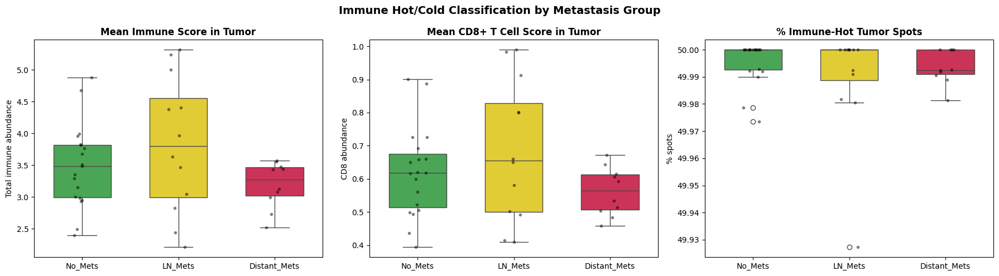

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='white')

sns.boxplot(data=immune_df, x='mets_group', y='mean_immune_score', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[0], width=0.6)
sns.stripplot(data=immune_df, x='mets_group', y='mean_immune_score', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[0])
axes[0].set_title('Mean Immune Score in Tumor', fontsize=12, fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('Total immune abundance')

sns.boxplot(data=immune_df, x='mets_group', y='mean_cd8_score', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[1], width=0.6)
sns.stripplot(data=immune_df, x='mets_group', y='mean_cd8_score', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[1])
axes[1].set_title('Mean CD8+ T Cell Score in Tumor', fontsize=12, fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('CD8 abundance')

sns.boxplot(data=immune_df, x='mets_group', y='pct_immune_hot', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[2], width=0.6)
sns.stripplot(data=immune_df, x='mets_group', y='pct_immune_hot', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[2])
axes[2].set_title('% Immune-Hot Tumor Spots', fontsize=12, fontweight='bold')
axes[2].set_xlabel(''); axes[2].set_ylabel('% spots')

plt.suptitle('Immune Hot/Cold Classification by Metastasis Group', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "1_immune_hot_cold", "immune_hot_cold_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Analysis 2: Tertiary Lymphoid Structures (TLS)

Identifies putative TLS by finding spatially clustered spots enriched for B cells (cB1-3) + T follicular helper cells (cTNI06) + DCs.

TLS are organized immune aggregates that predict favorable prognosis in CRC.

In [7]:
print("=" * 70)
print("ANALYSIS 2: TERTIARY LYMPHOID STRUCTURES (TLS)")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "2_tls"), exist_ok=True)

TLS_PATTERNS = {
    'B_cell': ['cB1', 'cB2', 'cB3'],
    'TFH': ['cTNI06'],
    'DC': ['cM03', 'cM04', 'cM05'],
    'Plasma': ['cP1', 'cP2', 'cP3'],
}

tls_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    abund = adata.obsm[ABUNDANCE_KEY]
    coords = adata.obsm['spatial']

    b_cols = get_column_matches(abund.columns, TLS_PATTERNS['B_cell'])
    tfh_cols = get_column_matches(abund.columns, TLS_PATTERNS['TFH'])
    dc_cols = get_column_matches(abund.columns, TLS_PATTERNS['DC'])

    b_score = abund[b_cols].sum(axis=1).values if b_cols else np.zeros(len(adata))
    tfh_score = abund[tfh_cols].sum(axis=1).values if tfh_cols else np.zeros(len(adata))
    dc_score = abund[dc_cols].sum(axis=1).values if dc_cols else np.zeros(len(adata))
    tls_score = b_score + tfh_score + dc_score

    threshold = np.percentile(tls_score, 90)
    tls_high = tls_score > threshold

    nn = NearestNeighbors(n_neighbors=min(20, len(coords))).fit(coords)
    dists, indices = nn.kneighbors(coords)
    spot_spacing = np.median(dists[:, 1])
    cluster_radius = 3 * spot_spacing

    tls_cluster = np.zeros(len(adata), dtype=bool)
    for i in range(len(adata)):
        if not tls_high[i]: continue
        neighbors_in_radius = dists[i] <= cluster_radius
        tls_neighbors = tls_high[indices[i][neighbors_in_radius]]
        if tls_neighbors.sum() >= 5:
            tls_cluster[i] = True

    n_tls = tls_cluster.sum()
    pct_tls = n_tls / len(adata) * 100

    tls_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_tls_spots': n_tls, 'pct_tls': pct_tls,
        'mean_b_score': b_score.mean(), 'mean_tfh_score': tfh_score.mean(),
    })
    print(f"  {sid}: {n_tls} TLS spots ({pct_tls:.1f}%)")

tls_df = pd.DataFrame(tls_results)
tls_df.to_csv(os.path.join(OUTPUT_DIR, "2_tls", "tls_summary.csv"), index=False)
print(f"Saved summary for {len(tls_df)} samples.")

ANALYSIS 2: TERTIARY LYMPHOID STRUCTURES (TLS)
  0: 561 TLS spots (8.4%)
  3: 397 TLS spots (7.1%)
  6: 590 TLS spots (9.2%)
  10: 527 TLS spots (8.6%)
  11: 610 TLS spots (8.3%)
  13: 483 TLS spots (8.2%)
  14: 586 TLS spots (8.5%)
  18: 579 TLS spots (9.2%)
  28: 568 TLS spots (8.1%)
  29: 529 TLS spots (7.8%)
  30: 436 TLS spots (6.7%)
  34: 471 TLS spots (7.5%)
  36: 584 TLS spots (8.5%)
  38: 503 TLS spots (7.2%)
  40: 675 TLS spots (9.4%)
  46: 591 TLS spots (8.7%)
  49: 581 TLS spots (8.9%)
  51: 459 TLS spots (7.2%)
  52: 590 TLS spots (8.8%)
  60: 519 TLS spots (8.0%)
  72: 620 TLS spots (9.2%)
  73: 558 TLS spots (8.5%)
  74: 664 TLS spots (9.5%)
  80: 591 TLS spots (9.1%)
  81: 678 TLS spots (9.3%)
  83: 603 TLS spots (8.1%)
  86: 526 TLS spots (7.0%)
  91: 588 TLS spots (8.8%)
  96: 662 TLS spots (9.5%)
  97: 492 TLS spots (8.0%)
  100: 532 TLS spots (7.4%)
  102: 662 TLS spots (9.7%)
  106: 639 TLS spots (9.0%)
  107: 560 TLS spots (7.9%)
  111: 609 TLS spots (8.6%)
  116:

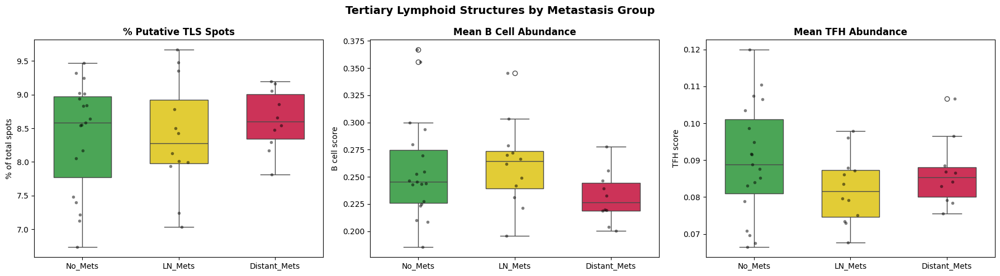

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='white')

sns.boxplot(data=tls_df, x='mets_group', y='pct_tls', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[0], width=0.6)
sns.stripplot(data=tls_df, x='mets_group', y='pct_tls', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[0])
axes[0].set_title('% Putative TLS Spots', fontsize=12, fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('% of total spots')

sns.boxplot(data=tls_df, x='mets_group', y='mean_b_score', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[1], width=0.6)
sns.stripplot(data=tls_df, x='mets_group', y='mean_b_score', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[1])
axes[1].set_title('Mean B Cell Abundance', fontsize=12, fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('B cell score')

sns.boxplot(data=tls_df, x='mets_group', y='mean_tfh_score', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[2], width=0.6)
sns.stripplot(data=tls_df, x='mets_group', y='mean_tfh_score', order=METS_ORDER,
              color='black', alpha=0.5, size=4, ax=axes[2])
axes[2].set_title('Mean TFH Abundance', fontsize=12, fontweight='bold')
axes[2].set_xlabel(''); axes[2].set_ylabel('TFH score')

plt.suptitle('Tertiary Lymphoid Structures by Metastasis Group', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "2_tls", "tls_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Analysis 3: Tumor Budding Zones

Tumor budding: isolated small clusters of tumor cells at the invasive front. Identified as stroma/IM spots with low but nonzero tumor signal — isolated tumor cells infiltrating into stroma. Strong prognostic indicator in CRC.

ANALYSIS 3: TUMOR BUDDING ZONES
  0: 278 budding spots (8.5%)
  3: 8 budding spots (1.0%)
  6: 127 budding spots (8.5%)
  10: 124 budding spots (4.8%)
  11: 42 budding spots (4.7%)
  13: 104 budding spots (9.8%)
  14: 314 budding spots (8.4%)
  18: 311 budding spots (9.9%)
  28: 2 budding spots (0.4%)
  29: 174 budding spots (6.4%)
  30: 0 budding spots (0.0%)
  34: 0 budding spots (0.0%)
  36: 485 budding spots (12.3%)
  38: 427 budding spots (10.0%)
  40: 226 budding spots (6.5%)
  46: 18 budding spots (1.7%)
  49: 624 budding spots (10.4%)
  51: 271 budding spots (9.7%)
  52: 469 budding spots (12.0%)
  60: 17 budding spots (1.4%)
  72: 82 budding spots (8.1%)
  73: 176 budding spots (7.5%)
  74: 401 budding spots (11.5%)
  80: 152 budding spots (4.9%)
  81: 640 budding spots (11.6%)
  83: 27 budding spots (3.9%)
  86: 30 budding spots (2.6%)
  91: 581 budding spots (13.6%)
  96: 532 budding spots (13.0%)
  97: 209 budding spots (6.8%)
  100: 0 budding spots (0.0%)
  102: 582 buddin

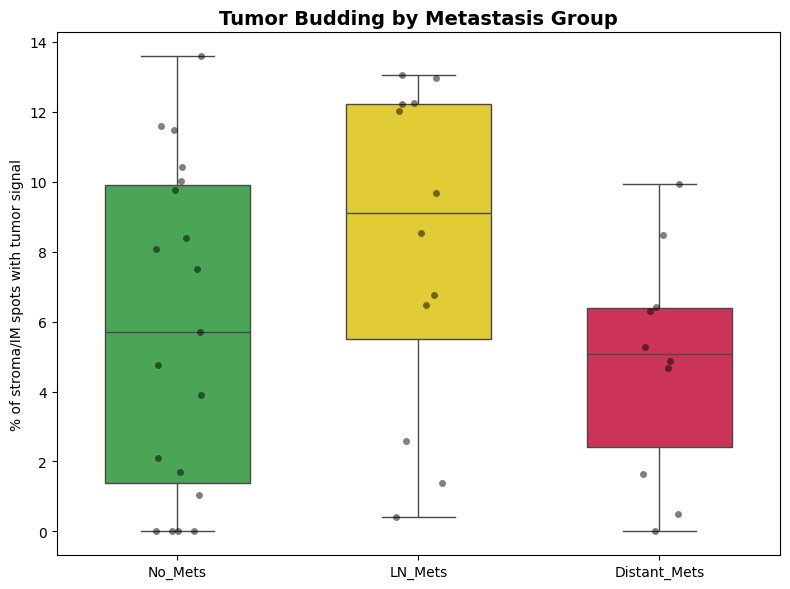

In [9]:
print("=" * 70)
print("ANALYSIS 3: TUMOR BUDDING ZONES")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "3_tumor_budding"), exist_ok=True)

budding_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    abund = adata.obsm[ABUNDANCE_KEY]
    tumor_cols = get_column_matches(abund.columns, ['Tumor'])
    tumor_score = abund[tumor_cols].sum(axis=1).values if tumor_cols else np.zeros(len(adata))

    if 'region' in adata.obs.columns:
        stroma_mask = adata.obs['region'].isin(['IM', 'Stroma'])
    else:
        stroma_mask = adata.obs['histology'] != 'cancer_cancer'

    tumor_positive = tumor_score[tumor_score > np.percentile(tumor_score, 50)]
    if len(tumor_positive) > 0:
        low_thresh = np.percentile(tumor_positive, 5)
        high_thresh = np.percentile(tumor_positive, 25)
    else:
        low_thresh, high_thresh = 0, 0

    budding_mask = stroma_mask.values & (tumor_score > low_thresh) & (tumor_score < high_thresh)
    n_budding = budding_mask.sum()
    n_im = stroma_mask.sum()
    pct_budding = n_budding / max(n_im, 1) * 100

    budding_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_budding_spots': n_budding, 'n_stroma_im_spots': n_im, 'pct_budding': pct_budding,
    })
    print(f"  {sid}: {n_budding} budding spots ({pct_budding:.1f}%)")

budding_df = pd.DataFrame(budding_results)
budding_df.to_csv(os.path.join(OUTPUT_DIR, "3_tumor_budding", "budding_summary.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
sns.boxplot(data=budding_df, x='mets_group', y='pct_budding', order=METS_ORDER,
            palette=METS_PALETTE, ax=ax, width=0.6)
sns.stripplot(data=budding_df, x='mets_group', y='pct_budding', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=ax)
ax.set_title('Tumor Budding by Metastasis Group', fontsize=14, fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('% of stroma/IM spots with tumor signal')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "3_tumor_budding", "budding_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Analysis 4: Hypoxic vs Normoxic Tumor

Scores tumor spots for hypoxia using a gene signature (HIF1A targets, Buffa et al. 2010) from the raw Visium counts. Hypoxic regions drive immune evasion and correlate with metastatic potential.

This is the one analysis that uses gene expression rather than Cell2Location abundances.

ANALYSIS 4: HYPOXIC vs NORMOXIC TUMOR
  0: mean hypoxia=3.506 (15 genes)
  3: mean hypoxia=2.987 (15 genes)
  6: mean hypoxia=2.108 (15 genes)
  10: mean hypoxia=0.046 (15 genes)
  11: mean hypoxia=1.464 (15 genes)
  13: mean hypoxia=1.123 (15 genes)
  14: mean hypoxia=1.289 (15 genes)
  18: mean hypoxia=0.719 (15 genes)
  28: mean hypoxia=1.263 (15 genes)
  29: mean hypoxia=0.682 (15 genes)
  30: mean hypoxia=0.428 (15 genes)
  34: mean hypoxia=4.044 (15 genes)
  36: mean hypoxia=0.495 (15 genes)
  38: mean hypoxia=1.212 (15 genes)
  40: mean hypoxia=3.535 (15 genes)
  46: mean hypoxia=0.498 (15 genes)
  49: mean hypoxia=0.716 (15 genes)
  51: mean hypoxia=0.310 (15 genes)
  52: mean hypoxia=2.977 (15 genes)
  60: mean hypoxia=0.856 (15 genes)
  72: mean hypoxia=1.857 (15 genes)
  73: mean hypoxia=0.261 (15 genes)
  74: mean hypoxia=0.481 (15 genes)
  80: mean hypoxia=8.403 (15 genes)
  81: mean hypoxia=0.264 (15 genes)
  83: mean hypoxia=0.767 (15 genes)
  86: mean hypoxia=2.543 (15 

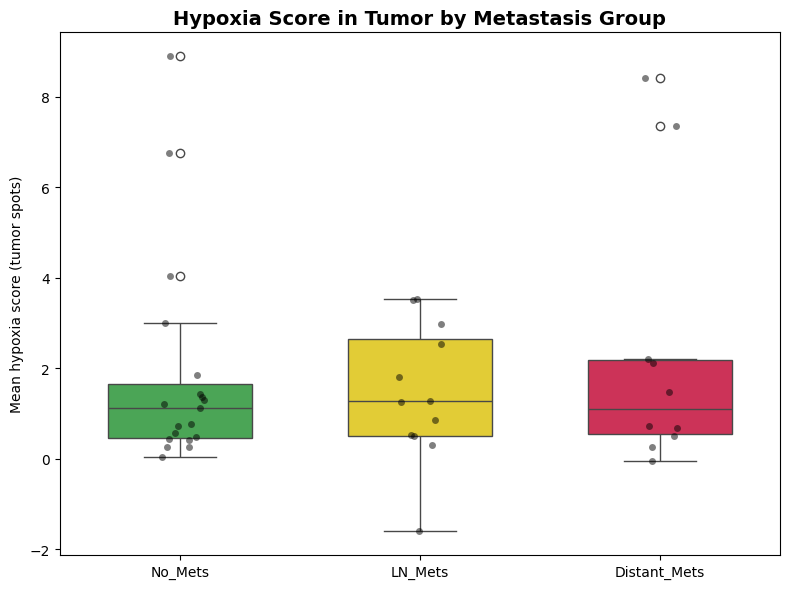

In [10]:
print("=" * 70)
print("ANALYSIS 4: HYPOXIC vs NORMOXIC TUMOR")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "4_hypoxia"), exist_ok=True)

HYPOXIA_GENES = [
    'VEGFA', 'SLC2A1', 'LDHA', 'PGK1', 'ALDOA', 'ENO1', 'CA9',
    'BNIP3', 'NDRG1', 'ADM', 'P4HA1', 'PGAM1', 'TPI1', 'GPI',
    'GAPDH', 'PKM', 'LOX', 'BNIP3L', 'HK2', 'PDK1'
]

hypoxia_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    available_genes = [g for g in HYPOXIA_GENES if g in adata.var_names]
    if len(available_genes) < 5:
        print(f"  {sid}: only {len(available_genes)} hypoxia genes, skipping")
        continue

    sc.tl.score_genes(adata, gene_list=available_genes, score_name='hypoxia_score', use_raw=False)
    hypoxia_score = adata.obs['hypoxia_score'].values

    if 'refined_region' in adata.obs.columns:
        tumor_mask = adata.obs['refined_region'].isin(['Tumor_epithelial', 'IM_tumor'])
    else:
        tumor_mask = adata.obs['histology'] == 'cancer_cancer'

    if tumor_mask.sum() == 0: continue

    mean_hyp = np.mean(hypoxia_score[tumor_mask])

    hypoxia_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_genes_used': len(available_genes), 'mean_hypoxia_tumor': mean_hyp,
    })
    print(f"  {sid}: mean hypoxia={mean_hyp:.3f} ({len(available_genes)} genes)")

hypoxia_df = pd.DataFrame(hypoxia_results)
hypoxia_df.to_csv(os.path.join(OUTPUT_DIR, "4_hypoxia", "hypoxia_summary.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
sns.boxplot(data=hypoxia_df, x='mets_group', y='mean_hypoxia_tumor', order=METS_ORDER,
            palette=METS_PALETTE, ax=ax, width=0.6)
sns.stripplot(data=hypoxia_df, x='mets_group', y='mean_hypoxia_tumor', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=ax)
ax.set_title('Hypoxia Score in Tumor by Metastasis Group', fontsize=14, fontweight='bold')
ax.set_xlabel(''); ax.set_ylabel('Mean hypoxia score (tumor spots)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "4_hypoxia", "hypoxia_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Analysis 5: Nerve Invasion Zones (Perineural)

Maps Schwann cell (cS33) co-localization with tumor cells. Perineural invasion is a prognostic factor in CRC.

ANALYSIS 5: NERVE INVASION ZONES (PERINEURAL)
  0: 1661 PNI spots (24.9%)
  3: 1239 PNI spots (22.2%)
  6: 1416 PNI spots (22.1%)
  10: 1505 PNI spots (24.5%)
  11: 1775 PNI spots (24.1%)
  13: 1450 PNI spots (24.5%)
  14: 1413 PNI spots (20.6%)
  18: 1186 PNI spots (18.8%)
  28: 1525 PNI spots (21.8%)
  29: 622 PNI spots (9.2%)
  30: 998 PNI spots (15.4%)
  34: 877 PNI spots (13.9%)
  36: 585 PNI spots (8.5%)
  38: 1684 PNI spots (24.2%)
  40: 1778 PNI spots (24.6%)
  46: 1640 PNI spots (24.0%)
  49: 693 PNI spots (10.7%)
  51: 1093 PNI spots (17.2%)
  52: 1554 PNI spots (23.1%)
  60: 1532 PNI spots (23.6%)
  72: 1626 PNI spots (24.2%)
  73: 1132 PNI spots (17.3%)
  74: 1724 PNI spots (24.6%)
  80: 1557 PNI spots (23.9%)
  81: 1661 PNI spots (22.8%)
  83: 1651 PNI spots (22.1%)
  86: 1663 PNI spots (22.2%)
  91: 1238 PNI spots (18.6%)
  96: 1394 PNI spots (20.0%)
  97: 1528 PNI spots (24.9%)
  100: 1595 PNI spots (22.2%)
  102: 1032 PNI spots (15.1%)
  106: 1739 PNI spots (24.5%)
  10

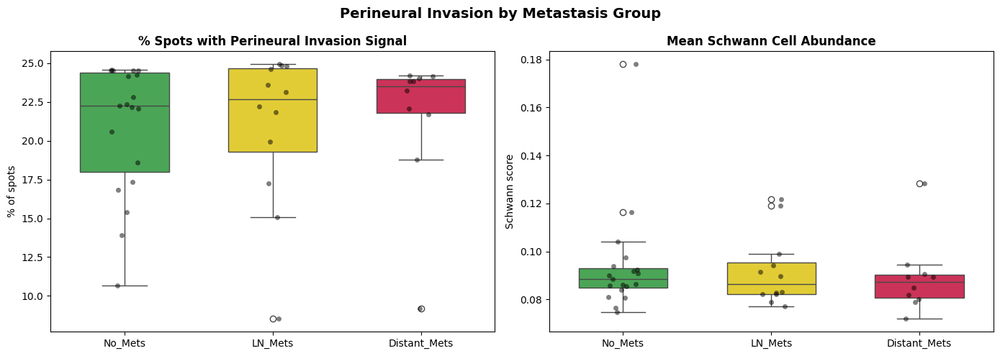

In [11]:
print("=" * 70)
print("ANALYSIS 5: NERVE INVASION ZONES (PERINEURAL)")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "5_nerve_invasion"), exist_ok=True)

nerve_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    abund = adata.obsm[ABUNDANCE_KEY]
    schwann_cols = get_column_matches(abund.columns, ['cS33'])
    tumor_cols = get_column_matches(abund.columns, ['Tumor'])

    schwann_score = abund[schwann_cols].sum(axis=1).values if schwann_cols else np.zeros(len(adata))
    tumor_score = abund[tumor_cols].sum(axis=1).values if tumor_cols else np.zeros(len(adata))

    schwann_thresh = np.percentile(schwann_score, 75)
    tumor_thresh = np.percentile(tumor_score, 50)
    pni_mask = (schwann_score > schwann_thresh) & (tumor_score > tumor_thresh)
    n_pni = pni_mask.sum()
    pct_pni = n_pni / len(adata) * 100

    nerve_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_pni_spots': n_pni, 'pct_pni': pct_pni, 'mean_schwann': schwann_score.mean(),
    })
    print(f"  {sid}: {n_pni} PNI spots ({pct_pni:.1f}%)")

nerve_df = pd.DataFrame(nerve_results)
nerve_df.to_csv(os.path.join(OUTPUT_DIR, "5_nerve_invasion", "nerve_invasion_summary.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')
sns.boxplot(data=nerve_df, x='mets_group', y='pct_pni', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[0], width=0.6)
sns.stripplot(data=nerve_df, x='mets_group', y='pct_pni', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=axes[0])
axes[0].set_title('% Spots with Perineural Invasion Signal', fontsize=12, fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('% of spots')

sns.boxplot(data=nerve_df, x='mets_group', y='mean_schwann', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[1], width=0.6)
sns.stripplot(data=nerve_df, x='mets_group', y='mean_schwann', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=axes[1])
axes[1].set_title('Mean Schwann Cell Abundance', fontsize=12, fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('Schwann score')

plt.suptitle('Perineural Invasion by Metastasis Group', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "5_nerve_invasion", "nerve_invasion_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Analysis 6: Vascular Invasion Zones (Lymphovascular)

Maps endothelial cell (cS01-14) co-localization with tumor cells. Lymphovascular invasion is a major prognostic factor in CRC. Lymphatic endothelium (cS06) reported separately.

ANALYSIS 6: VASCULAR INVASION ZONES (LYMPHOVASCULAR)
  0: 1573 LVI spots (23.6%), 1469 lymphatic
  3: 983 LVI spots (17.6%), 596 lymphatic
  6: 1136 LVI spots (17.7%), 932 lymphatic
  10: 1413 LVI spots (23.0%), 1271 lymphatic
  11: 1662 LVI spots (22.6%), 1203 lymphatic
  13: 1311 LVI spots (22.2%), 1107 lymphatic
  14: 1396 LVI spots (20.4%), 1088 lymphatic
  18: 1109 LVI spots (17.6%), 970 lymphatic
  28: 1235 LVI spots (17.7%), 822 lymphatic
  29: 1023 LVI spots (15.1%), 732 lymphatic
  30: 1019 LVI spots (15.7%), 847 lymphatic
  34: 606 LVI spots (9.6%), 265 lymphatic
  36: 635 LVI spots (9.2%), 412 lymphatic
  38: 1394 LVI spots (20.0%), 1240 lymphatic
  40: 1776 LVI spots (24.6%), 1738 lymphatic
  46: 1474 LVI spots (21.6%), 1167 lymphatic
  49: 1084 LVI spots (16.7%), 983 lymphatic
  51: 629 LVI spots (9.9%), 377 lymphatic
  52: 1346 LVI spots (20.0%), 1231 lymphatic
  60: 1342 LVI spots (20.7%), 1168 lymphatic
  72: 1494 LVI spots (22.3%), 1072 lymphatic
  73: 1057 LVI spots (

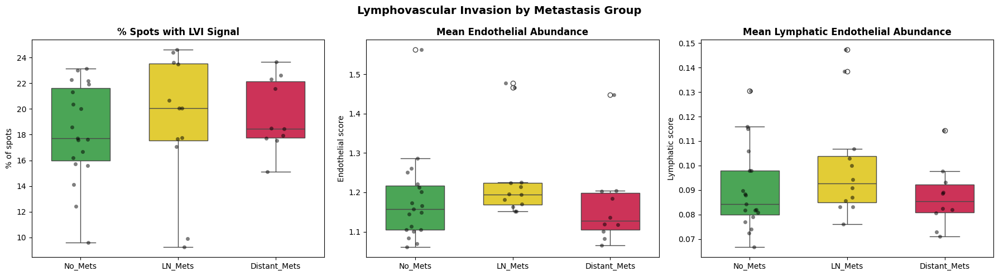

In [12]:
print("=" * 70)
print("ANALYSIS 6: VASCULAR INVASION ZONES (LYMPHOVASCULAR)")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "6_vascular_invasion"), exist_ok=True)

ENDO_PATTERNS = ['cS01', 'cS02', 'cS03', 'cS04', 'cS05', 'cS06', 'cS07',
                  'cS08', 'cS09', 'cS10', 'cS11', 'cS12', 'cS13', 'cS14']
LYMPHATIC_PATTERNS = ['cS06']

vasc_results = []

for _, row in meta.iterrows():
    sid = str(row['deident'])
    adata = load_sample(sid)
    if adata is None: continue

    abund = adata.obsm[ABUNDANCE_KEY]
    endo_cols = get_column_matches(abund.columns, ENDO_PATTERNS)
    lymph_cols = get_column_matches(abund.columns, LYMPHATIC_PATTERNS)
    tumor_cols = get_column_matches(abund.columns, ['Tumor'])

    endo_score = abund[endo_cols].sum(axis=1).values if endo_cols else np.zeros(len(adata))
    lymph_score = abund[lymph_cols].sum(axis=1).values if lymph_cols else np.zeros(len(adata))
    tumor_score = abund[tumor_cols].sum(axis=1).values if tumor_cols else np.zeros(len(adata))

    endo_thresh = np.percentile(endo_score, 75)
    tumor_thresh = np.percentile(tumor_score, 50)
    lvi_mask = (endo_score > endo_thresh) & (tumor_score > tumor_thresh)
    n_lvi = lvi_mask.sum()
    pct_lvi = n_lvi / len(adata) * 100

    lymph_thresh = np.percentile(lymph_score, 75) if lymph_cols else 0
    lymph_lvi = (lymph_score > lymph_thresh) & (tumor_score > tumor_thresh)
    n_lymph_lvi = lymph_lvi.sum()

    vasc_results.append({
        'sample_id': sid, 'mets_group': row['mets_group'],
        'n_lvi_spots': n_lvi, 'pct_lvi': pct_lvi, 'n_lymphatic_lvi': n_lymph_lvi,
        'mean_endo': endo_score.mean(), 'mean_lymphatic': lymph_score.mean(),
    })
    print(f"  {sid}: {n_lvi} LVI spots ({pct_lvi:.1f}%), {n_lymph_lvi} lymphatic")

vasc_df = pd.DataFrame(vasc_results)
vasc_df.to_csv(os.path.join(OUTPUT_DIR, "6_vascular_invasion", "vascular_invasion_summary.csv"), index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='white')
sns.boxplot(data=vasc_df, x='mets_group', y='pct_lvi', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[0], width=0.6)
sns.stripplot(data=vasc_df, x='mets_group', y='pct_lvi', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=axes[0])
axes[0].set_title('% Spots with LVI Signal', fontsize=12, fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('% of spots')

sns.boxplot(data=vasc_df, x='mets_group', y='mean_endo', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[1], width=0.6)
sns.stripplot(data=vasc_df, x='mets_group', y='mean_endo', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=axes[1])
axes[1].set_title('Mean Endothelial Abundance', fontsize=12, fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('Endothelial score')

sns.boxplot(data=vasc_df, x='mets_group', y='mean_lymphatic', order=METS_ORDER,
            palette=METS_PALETTE, ax=axes[2], width=0.6)
sns.stripplot(data=vasc_df, x='mets_group', y='mean_lymphatic', order=METS_ORDER,
              color='black', alpha=0.5, size=5, ax=axes[2])
axes[2].set_title('Mean Lymphatic Endothelial Abundance', fontsize=12, fontweight='bold')
axes[2].set_xlabel(''); axes[2].set_ylabel('Lymphatic score')

plt.suptitle('Lymphovascular Invasion by Metastasis Group', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "6_vascular_invasion", "vascular_invasion_by_mets.png"), dpi=300, bbox_inches='tight')
plt.show()

## Spatial Feature Maps — Representative Samples

For each representative sample (38=No Mets, 107=LN Mets, 80=Distant Mets), generate a combined spatial map showing all 6 feature scores overlaid on H&E.

GENERATING SPATIAL MAPS FOR REPRESENTATIVE SAMPLES


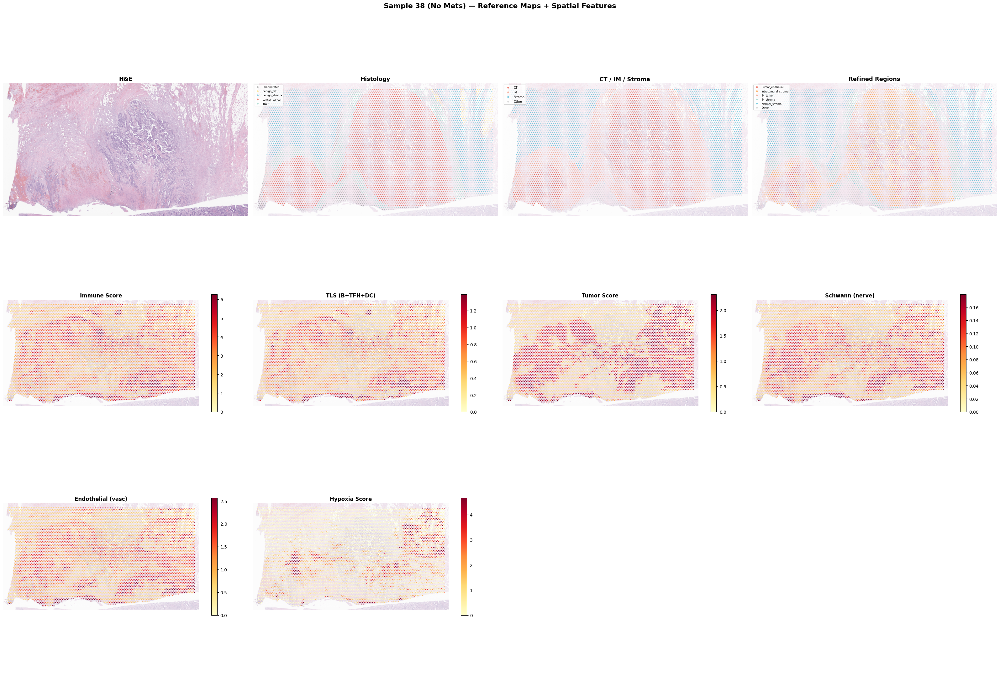

  38 done


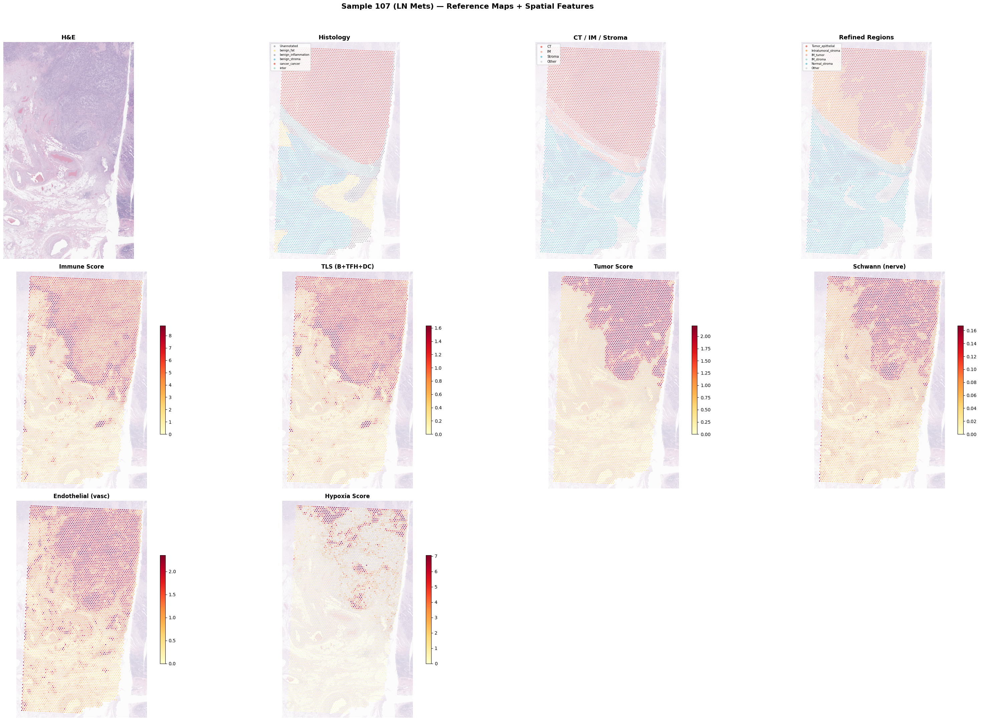

  107 done


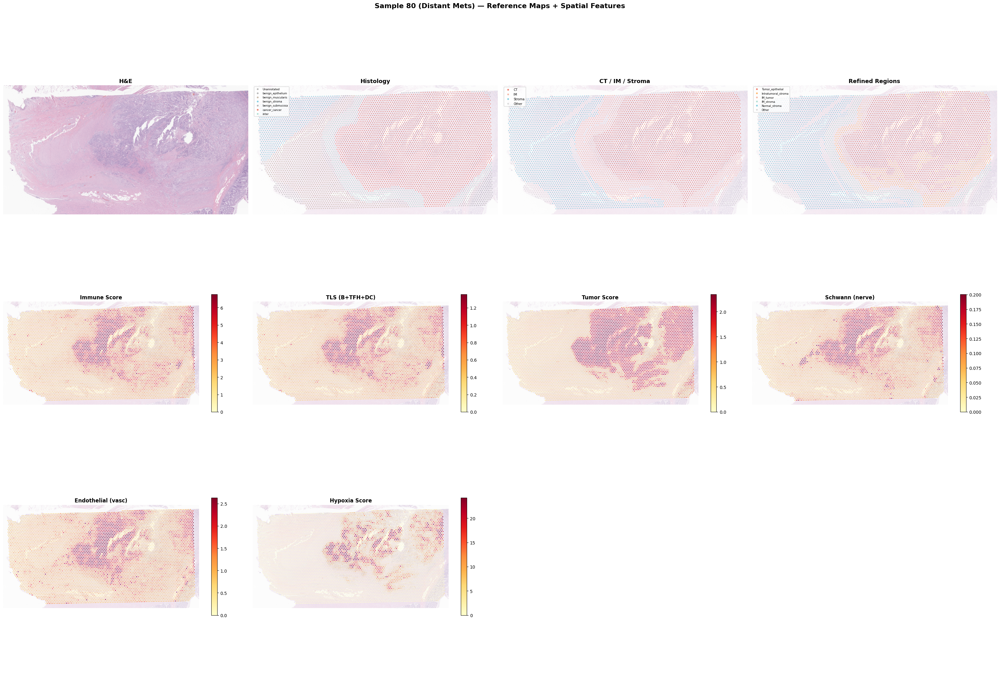

  80 done
All outputs saved to: /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_Features
Done!


In [15]:
print("=" * 70)
print("GENERATING SPATIAL MAPS FOR REPRESENTATIVE SAMPLES")
print("=" * 70)

os.makedirs(os.path.join(OUTPUT_DIR, "spatial_maps"), exist_ok=True)

HYPOXIA_GENES = [
    'VEGFA', 'SLC2A1', 'LDHA', 'PGK1', 'ALDOA', 'ENO1', 'CA9',
    'BNIP3', 'NDRG1', 'ADM', 'P4HA1', 'PGAM1', 'TPI1', 'GPI',
    'GAPDH', 'PKM', 'LOX', 'BNIP3L', 'HK2', 'PDK1'
]

HIST_COLORS = {
    'cancer_cancer': '#E64B35', 'benign_stroma': '#4DBBD5',
    'benign_fat': '#F9E076', 'inter': '#91D1C2', 'stroma': '#8491B4',
    'benign_muscularis': '#B09C85', 'Unannotated': '#999999',
}
REGION_COLORS_MAP = {'CT': '#E64B35', 'IM': '#F39B7F', 'Stroma': '#4DBBD5', 'Other': '#CCCCCC'}
REFINED_COLORS_MAP = {
    'Tumor_epithelial': '#E64B35', 'Intratumoral_stroma': '#FF9933',
    'IM_tumor': '#F39B7F', 'IM_stroma': '#91D1C2',
    'Normal_stroma': '#4DBBD5', 'Other': '#CCCCCC',
}

for mets_label, sid in EXAMPLE_SAMPLES.items():
    adata = load_sample(sid)
    if adata is None:
        print(f"  {sid}: not found")
        continue

    abund = adata.obsm[ABUNDANCE_KEY]
    coords = adata.obsm['spatial']
    img_cropped, x_cr, y_cr = get_he_cropped(adata)
    histology = adata.obs['histology'].values

    # Get region annotations if available
    region = adata.obs['region'].values if 'region' in adata.obs.columns else np.full(len(adata), 'NA')
    refined = adata.obs['refined_region'].values if 'refined_region' in adata.obs.columns else np.full(len(adata), 'NA')

    # Compute all feature scores
    immune_cols = get_column_matches(abund.columns, all_immune_patterns)
    b_cols = get_column_matches(abund.columns, ['cB1', 'cB2', 'cB3'])
    tfh_cols = get_column_matches(abund.columns, ['cTNI06'])
    dc_cols = get_column_matches(abund.columns, ['cM03', 'cM04', 'cM05'])
    schwann_cols = get_column_matches(abund.columns, ['cS33'])
    endo_cols = get_column_matches(abund.columns, ENDO_PATTERNS)
    tumor_cols = get_column_matches(abund.columns, ['Tumor'])

    scores = {
        'Immune Score': abund[immune_cols].sum(axis=1).values,
        'TLS (B+TFH+DC)': (abund[b_cols].sum(axis=1).values +
                            abund[tfh_cols].sum(axis=1).values +
                            abund[dc_cols].sum(axis=1).values),
        'Tumor Score': abund[tumor_cols].sum(axis=1).values,
        'Schwann (nerve)': abund[schwann_cols].sum(axis=1).values if schwann_cols else np.zeros(len(adata)),
        'Endothelial (vasc)': abund[endo_cols].sum(axis=1).values,
    }

    hyp_genes = [g for g in HYPOXIA_GENES if g in adata.var_names]
    if len(hyp_genes) >= 5:
        sc.tl.score_genes(adata, gene_list=hyp_genes, score_name='hypoxia_score', use_raw=False)
        scores['Hypoxia Score'] = adata.obs['hypoxia_score'].values

    # ================================================================
    # 3-ROW FIGURE
    # Row 1: Reference maps (H&E, Histology, CT/IM/Stroma, Refined)
    # Row 2-3: Feature scores on H&E (6 panels)
    # ================================================================
    fig, axes = plt.subplots(3, 4, figsize=(32, 22), facecolor='white')

    # --- ROW 1: REFERENCE MAPS ---

    # Panel 1: H&E alone
    ax = axes[0, 0]
    ax.imshow(img_cropped)
    ax.set_title('H&E', fontsize=13, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')

    # Panel 2: H&E + Histology
    ax = axes[0, 1]
    ax.imshow(img_cropped, alpha=0.3)
    for h_label in sorted(np.unique(histology)):
        mask = histology == h_label
        color = HIST_COLORS.get(h_label, '#999999')
        ax.scatter(x_cr[mask], y_cr[mask], c=color, s=4,
                   edgecolors='none', alpha=0.7, label=h_label)
    ax.set_title('Histology', fontsize=13, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.legend(fontsize=6, markerscale=2, loc='upper left', framealpha=0.8, facecolor='white')

    # Panel 3: H&E + CT/IM/Stroma
    ax = axes[0, 2]
    ax.imshow(img_cropped, alpha=0.3)
    for r_label in ['CT', 'IM', 'Stroma', 'Other']:
        mask = region == r_label
        if isinstance(mask, pd.Series):
            mask = mask.values
        if mask.sum() > 0:
            ax.scatter(x_cr[mask], y_cr[mask], c=REGION_COLORS_MAP[r_label], s=4,
                       edgecolors='none', alpha=0.7, label=r_label)
    ax.set_title('CT / IM / Stroma', fontsize=13, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.legend(fontsize=7, markerscale=2, loc='upper left', framealpha=0.8, facecolor='white')

    # Panel 4: H&E + Refined regions
    ax = axes[0, 3]
    ax.imshow(img_cropped, alpha=0.3)
    for ref_label in ['Tumor_epithelial', 'Intratumoral_stroma', 'IM_tumor',
                       'IM_stroma', 'Normal_stroma', 'Other']:
        mask = refined == ref_label
        if isinstance(mask, pd.Series):
            mask = mask.values
        if mask.sum() > 0:
            ax.scatter(x_cr[mask], y_cr[mask], c=REFINED_COLORS_MAP[ref_label], s=4,
                       edgecolors='none', alpha=0.7, label=ref_label)
    ax.set_title('Refined Regions', fontsize=13, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    ax.legend(fontsize=6, markerscale=2, loc='upper left', framealpha=0.8, facecolor='white')

    # --- ROWS 2-3: FEATURE SCORES ---
    feature_axes = list(axes[1].flat) + list(axes[2].flat)

    for idx, (title, vals) in enumerate(scores.items()):
        ax = feature_axes[idx]
        ax.imshow(img_cropped, alpha=0.4)
        vmax = np.percentile(vals, 98) if np.percentile(vals, 98) > 0 else 1
        sc_plot = ax.scatter(x_cr, y_cr, c=vals, cmap='YlOrRd', s=4,
                             edgecolors='none', vmin=0, vmax=vmax)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_aspect('equal')
        ax.axis('off')
        plt.colorbar(sc_plot, ax=ax, shrink=0.5)

    # Turn off unused axes
    for idx in range(len(scores), len(feature_axes)):
        feature_axes[idx].axis('off')

    plt.suptitle(
        f'Sample {sid} ({mets_label.replace("_", " ")}) — Reference Maps + Spatial Features',
        fontsize=16, fontweight='bold', y=0.98
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(
        os.path.join(OUTPUT_DIR, "spatial_maps", f"features_{sid}_{mets_label}.png"),
        dpi=200, bbox_inches='tight'
    )
    plt.show()
    print(f"  {sid} done")

print("All outputs saved to: " + OUTPUT_DIR)
print("Done!")